In [1]:
from pathlib import Path
import json
import re
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

DATA_ROOT = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "scipostlayout"
    / "poster"
    / "png"
)

FEATURE_ROOT = PROJECT_ROOT / "data" / "processed" / "features"
FEATURE_ROOT.mkdir(parents=True, exist_ok=True)

SPLITS = ("train", "dev", "test")

print("Project root:", PROJECT_ROOT)
print("Source data exists:", DATA_ROOT.exists())
print("Feature output:", FEATURE_ROOT)

Project root: /mnt/c/Users/rahul/Desktop/Projects/infographix
Source data exists: True
Feature output: /mnt/c/Users/rahul/Desktop/Projects/infographix/data/processed/features


In [2]:
splits = {}

for split in SPLITS:
    json_path = DATA_ROOT / f"{split}.json"

    with json_path.open("r", encoding="utf-8") as f:
        splits[split] = json.load(f)

categories = pd.DataFrame(splits["train"]["categories"])

category_names = {
    category["id"]: category["name"]
    for category in splits["train"]["categories"]
}

canonical_categories = {
    (c["id"], c["name"], c.get("supercategory"))
    for c in splits["train"]["categories"]
}

for split in ("dev", "test"):
    split_categories = {
        (c["id"], c["name"], c.get("supercategory"))
        for c in splits[split]["categories"]
    }

    assert split_categories == canonical_categories, (
        f"Category definitions differ in {split}"
    )

display(categories[["id", "name", "supercategory"]])

print("Number of categories:", len(category_names))

,id,name,supercategory
0,674852286,Author Info,root
1,487601213,Title,root
2,3731383018,Figure,root
3,2871247081,Text,root
4,2837082304,List,root
5,481284670,Section,root
6,788514875,Caption,root
7,3405481596,Table,root
8,3591166397,Unknown,root


Number of categories: 9


In [3]:
def prepare_split(split):
    images_df = pd.DataFrame(splits[split]["images"]).copy()
    annotations_df = pd.DataFrame(
        splits[split]["annotations"]
    ).copy()

    # Basic image metadata validation.
    assert images_df["id"].is_unique, (
        f"Duplicate image IDs in {split}"
    )

    assert images_df["file_name"].is_unique, (
        f"Duplicate filenames in {split}"
    )

    assert (images_df["width"] > 0).all()
    assert (images_df["height"] > 0).all()

    # Every annotation must refer to an image in this split.
    image_ids = set(images_df["id"])

    assert annotations_df["image_id"].isin(image_ids).all(), (
        f"Orphan annotations in {split}"
    )

    # Convert COCO-style bbox lists into numeric columns.
    bbox_values = pd.DataFrame(
        annotations_df["bbox"].tolist(),
        columns=["x", "y", "w", "h"],
        index=annotations_df.index,
    ).apply(pd.to_numeric, errors="coerce")

    annotations_df = pd.concat(
        [annotations_df, bbox_values], axis=1
    )

    image_meta = images_df.set_index("id")

    annotations_df["image_width"] = (
        annotations_df["image_id"].map(image_meta["width"])
    )

    annotations_df["image_height"] = (
        annotations_df["image_id"].map(image_meta["height"])
    )

    finite = np.isfinite(
        annotations_df[["x", "y", "w", "h"]]
    ).all(axis=1)

    valid = (
        finite
        & (annotations_df["x"] >= 0)
        & (annotations_df["y"] >= 0)
        & (annotations_df["w"] > 0)
        & (annotations_df["h"] > 0)
        & (
            annotations_df["x"] + annotations_df["w"]
            <= annotations_df["image_width"]
        )
        & (
            annotations_df["y"] + annotations_df["h"]
            <= annotations_df["image_height"]
        )
        & annotations_df["category_id"].isin(category_names)
    )

    annotations_df["is_valid"] = valid

    quality = {
        "split": split,
        "images": len(images_df),
        "annotations": len(annotations_df),
        "valid_annotations": int(valid.sum()),
        "rejected_annotations": int((~valid).sum()),
    }

    valid_annotations = annotations_df.loc[valid].copy()

    return images_df, valid_annotations, quality


prepared = {}
quality_rows = []

for split in SPLITS:
    image_df, valid_ann_df, quality = prepare_split(split)

    prepared[split] = {
        "images": image_df,
        "annotations": valid_ann_df,
    }

    quality_rows.append(quality)

quality_df = pd.DataFrame(quality_rows)
display(quality_df)

,split,images,annotations,valid_annotations,rejected_annotations
0,train,6855,168313,168220,93
1,dev,500,12141,12136,5
2,test,500,12243,12241,2


In [4]:
def add_geometry_features(annotations_df):
    df = annotations_df.copy()

    # Normalize positions and sizes relative to each poster.
    df["rel_x"] = df["x"] / df["image_width"]
    df["rel_y"] = df["y"] / df["image_height"]

    df["rel_w"] = df["w"] / df["image_width"]
    df["rel_h"] = df["h"] / df["image_height"]

    df["rel_area"] = df["rel_w"] * df["rel_h"]

    # Center coordinates, normalized to [0, 1].
    df["center_x"] = (
        df["x"] + df["w"] / 2
    ) / df["image_width"]

    df["center_y"] = (
        df["y"] + df["h"] / 2
    ) / df["image_height"]

    return df


for split in SPLITS:
    prepared[split]["annotations"] = add_geometry_features(
        prepared[split]["annotations"]
    )

prepared["train"]["annotations"][
    [
        "image_id",
        "category_id",
        "rel_x",
        "rel_y",
        "rel_w",
        "rel_h",
        "rel_area",
        "center_x",
        "center_y",
    ]
].head()

,image_id,category_id,rel_x,rel_y,rel_w,rel_h,rel_area,center_x,center_y
0,2921933168,487601213,0.221872,0.063968,0.547222,0.037276,0.020398,0.495483,0.082606
1,2921933168,674852286,0.308733,0.112647,0.354267,0.023243,0.008234,0.485866,0.124268
2,2921933168,481284670,0.512855,0.165272,0.253757,0.014033,0.003561,0.639733,0.172288
3,2921933168,481284670,0.068625,0.165710,0.390873,0.027190,0.010628,0.264062,0.179305
4,2921933168,2871247081,0.066143,0.200356,0.416311,0.245147,0.102057,0.274298,0.322929


In [5]:
def category_slug(name):
    """Create stable, readable feature names from category labels."""
    slug = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    return slug or "unnamed"


def build_poster_features(split):
    image_df = prepared[split]["images"].copy()
    ann_df = prepared[split]["annotations"].copy()

    # Overall poster-level properties.
    features = pd.DataFrame({
        "poster_id": image_df["id"].to_numpy(),
        "aspect_ratio": (
            image_df["width"] / image_df["height"]
        ).to_numpy(),
        "pixel_width": image_df["width"].to_numpy(),
        "pixel_height": image_df["height"].to_numpy(),
    })

    # Poster-wide annotation counts.
    counts = (
        ann_df.groupby("image_id")
        .size()
        .reindex(image_df["id"], fill_value=0)
        .to_numpy()
    )

    features["element_count"] = counts

    # Number of boxes divided by normalized poster area.
    # Since every normalized poster area is 1, this equals count.
    features["element_density"] = counts.astype(float)

    # Approximate summed area of all valid boxes, including overlaps.
    area_sum = (
        ann_df.groupby("image_id")["rel_area"]
        .sum()
        .reindex(image_df["id"], fill_value=0)
        .to_numpy()
    )

    features["sum_bbox_area_ratio"] = area_sum

    # Geometry summaries for all elements.
    geometry_summary = ann_df.groupby("image_id").agg(
        median_element_area=("rel_area", "median"),
        median_element_width=("rel_w", "median"),
        median_element_height=("rel_h", "median"),
        median_center_x=("center_x", "median"),
        median_center_y=("center_y", "median"),
        spread_center_x=("center_x", lambda s: s.std(ddof=0)),
        spread_center_y=("center_y", lambda s: s.std(ddof=0)),
    )

    geometry_summary = geometry_summary.reindex(image_df["id"])

    geometry_summary.index = image_df.index

    features = pd.concat(
        [features, geometry_summary.reset_index(drop=True)],
        axis=1,
    )

    # One group of features for each category.
    for category_id, category_name in category_names.items():
        slug = category_slug(category_name)

        subset = ann_df.loc[
            ann_df["category_id"] == category_id
        ]

        # Category counts, including posters with zero of this category.
        category_counts = (
            subset.groupby("image_id")
            .size()
            .reindex(image_df["id"], fill_value=0)
            .to_numpy()
        )

        features[f"count_{slug}"] = category_counts

        features[f"proportion_{slug}"] = np.divide(
            category_counts,
            counts,
            out=np.zeros(len(counts), dtype=float),
            where=counts > 0,
        )

        summary = subset.groupby("image_id").agg(
            area=("rel_area", "median"),
            width=("rel_w", "median"),
            height=("rel_h", "median"),
            center_x=("center_x", "median"),
            center_y=("center_y", "median"),
            spread_x=("center_x", lambda s: s.std(ddof=0)),
            spread_y=("center_y", lambda s: s.std(ddof=0)),
        )

        summary = summary.reindex(image_df["id"])
        summary.index = image_df.index

        # Missing geometry summaries mean no elements of that category.
        summary = summary.fillna(0)

        for stat in summary.columns:
            features[f"{stat}_{slug}"] = summary[stat].to_numpy()

    # Record split separately; do not use it as a model feature.
    features.insert(1, "split", split)

    return features


feature_frames = {
    split: build_poster_features(split)
    for split in SPLITS
}

for split, frame in feature_frames.items():
    print(
        f"{split}: {frame.shape[0]} posters, "
        f"{frame.shape[1] - 2} features"
    )

display(feature_frames["train"].head())

train: 6855 posters, 94 features
dev: 500 posters, 94 features
test: 500 posters, 94 features


,poster_id,split,aspect_ratio,pixel_width,pixel_height,element_count,element_density,sum_bbox_area_ratio,median_element_area,median_element_width,...,spread_y_table,count_unknown,proportion_unknown,area_unknown,width_unknown,height_unknown,center_x_unknown,center_y_unknown,spread_x_unknown,spread_y_unknown
0,2921933168,train,0.706838,827,1170,40,40.0,0.397554,0.005622,0.142080,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2541841589,train,1.285714,5400,4200,14,14.0,0.794552,0.033556,0.607959,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1738374677,train,0.713675,835,1170,15,15.0,0.673050,0.023426,0.414541,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1532752890,train,1.500000,7200,4800,39,39.0,0.514315,0.013637,0.135683,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1584483332,train,0.706838,827,1170,24,24.0,0.735865,0.014026,0.275823,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:

# Validate the engineered feature matrix and handle NaN values.

feature_columns = [
    column
    for column in feature_frames["train"].columns
    if column not in {
        "poster_id",
        "split",
        "pixel_width",
        "pixel_height",
    }
]

for split in SPLITS:
    df = feature_frames[split]

    X = df[feature_columns]

    # 1. Check for non-numeric columns.
    assert X.select_dtypes(exclude=[np.number]).empty, (
        f"Non-numeric features found in {split}"
    )

    # 2. Identify columns containing NaN or infinity.
    finite_mask = np.isfinite(X.to_numpy(dtype=float))

    bad_rows = ~finite_mask.all(axis=1)

    print(f"\n{split.upper()}")
    print("Posters with NaN/inf:", int(bad_rows.sum()))

    if bad_rows.any():
        print(
            "Affected poster IDs:",
            df.loc[bad_rows, "poster_id"].tolist()
        )

    # 3. Fix NaN values in spatial spread features.
    # A single element has zero spread by definition.
    spread_columns = [
        c for c in feature_columns
        if c.startswith("spread_")
    ]

    df.loc[:, spread_columns] = (
        df[spread_columns].fillna(0)
    )

    # 4. Drop posters that still have NaN or infinity.
    X = df[feature_columns]
    finite_mask = np.isfinite(X.to_numpy(dtype=float))
    bad_rows = ~finite_mask.all(axis=1)

    if bad_rows.any():
        feature_frames[split] = (
            df.loc[~bad_rows].reset_index(drop=True)
        )

        print(
            "Dropped posters:",
            int(bad_rows.sum())
        )
    else:
        print("No posters needed to be dropped.")

    # 5. Confirm the remaining data is valid.
    X_clean = feature_frames[split][feature_columns]

    assert np.isfinite(X_clean.to_numpy(dtype=float)).all(), (
        f"NaN or infinity remains in {split}"
    )

    assert feature_frames[split]["poster_id"].is_unique

    print(
        "Remaining posters:",
        len(feature_frames[split])
    )

print("\nFeature validation completed.")



TRAIN
Posters with NaN/inf: 2
Affected poster IDs: [3734710495, 3281866599]
Dropped posters: 2
Remaining posters: 6853

DEV
Posters with NaN/inf: 0
No posters needed to be dropped.
Remaining posters: 500

TEST
Posters with NaN/inf: 0
No posters needed to be dropped.
Remaining posters: 500

Feature validation completed.


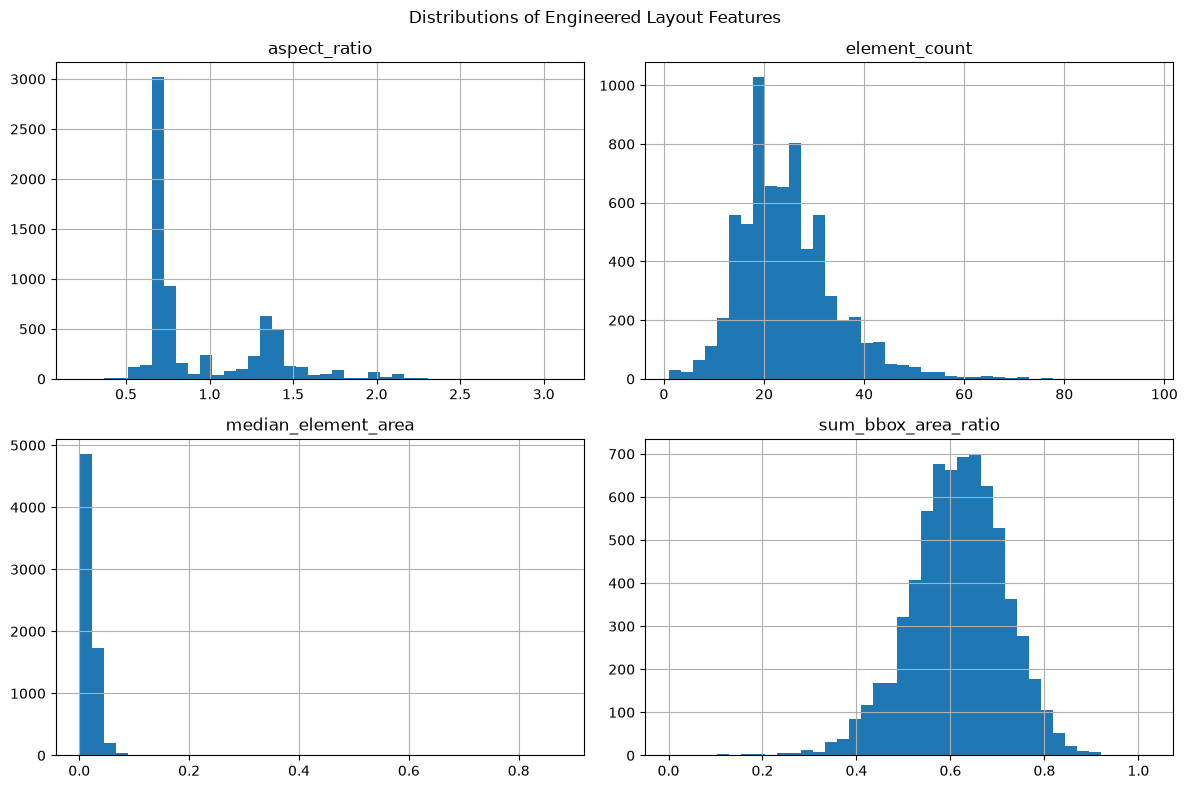

In [12]:
key_features = [
    "aspect_ratio",
    "element_count",
    "median_element_area",
    "sum_bbox_area_ratio",
]

available = [
    column
    for column in key_features
    if column in feature_frames["train"].columns
]

feature_frames["train"][available].hist(
    bins=40,
    figsize=(12, 8),
)

plt.suptitle("Distributions of Engineered Layout Features")
plt.tight_layout()
plt.show()

In [13]:
for split, frame in feature_frames.items():
    output_path = FEATURE_ROOT / f"{split}_features.parquet"

    frame.to_parquet(output_path, index=False)

    print(f"Saved: {output_path}")

# Save the exact ordered schema for later inference.
schema_path = FEATURE_ROOT / "feature_schema.json"

schema = {
    "feature_columns": feature_columns,
    "category_names": {
        str(k): v for k, v in category_names.items()
    },
    "version": "1.0.0",
}

schema_path.write_text(
    json.dumps(schema, indent=2),
    encoding="utf-8",
)

print("Saved schema:", schema_path)

Saved: /mnt/c/Users/rahul/Desktop/Projects/infographix/data/processed/features/train_features.parquet
Saved: /mnt/c/Users/rahul/Desktop/Projects/infographix/data/processed/features/dev_features.parquet
Saved: /mnt/c/Users/rahul/Desktop/Projects/infographix/data/processed/features/test_features.parquet
Saved schema: /mnt/c/Users/rahul/Desktop/Projects/infographix/data/processed/features/feature_schema.json


In [14]:
from sklearn.preprocessing import StandardScaler

# Remove constant features based on training data only.
feature_std = feature_frames["train"][feature_columns].std()

model_features = [
    column
    for column in feature_columns
    if feature_std[column] > 0
]

X_train = feature_frames["train"][model_features].copy()
X_dev = feature_frames["dev"][model_features].copy()
X_test = feature_frames["test"][model_features].copy()

# Fit only on the training split.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# Reuse the learned training parameters.
X_dev_scaled = scaler.transform(X_dev)
X_test_scaled = scaler.transform(X_test)

print("Model features:", len(model_features))
print("Train shape:", X_train_scaled.shape)
print("Dev shape:", X_dev_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Model features: 92
Train shape: (6853, 92)
Dev shape: (500, 92)
Test shape: (500, 92)
